# Spectrogram Analysis and Input Design

This notebook loads the prepared Log-Mel spectrograms, compares STFT and Log-Mel representations, analyses the input dimensions and fixes the input shape of the custom CNN.

Before running it, build the feature cache once from the repository root:

```bash
python -m scripts.prepare_features
```

| Step 2.1 task | Section |
|---|---|
| Load and explore prepared spectrograms | 1 |
| Visualize different spectrogram representations | 2, 3 |
| Compare STFT and Log-Mel | 3 |
| Analyze input dimensions and structure | 4 |
| Select the representation for CNN training | 5 |
| Define the final CNN input shape | 6, 7 |

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa.display
import torch
from tqdm.auto import tqdm

from src.audio_preprocessing import SAMPLE_RATE, preprocess_audio
from src.data_loader import CLASS_NAMES, audio_file, split_dataframe
from src.features import load_feature_cache
from src.paths import get_dataset_path
from src.spectrograms import HOP_LENGTH
from src import spectrogram_analysis as sa

FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

## 1. Load the prepared spectrograms

The cache holds one normalized Log-Mel spectrogram per clip (8,732 in total), in the same order as the metadata index. It is memory-mapped, so only the rows that are used are read from disk.

In [2]:
X, index = load_feature_cache()

print("Feature array:", X.shape, X.dtype)
print(f"Size on disk:  {X.nbytes / 1024 ** 3:.2f} GB")
picked = np.sort(np.random.default_rng(0).choice(len(X), min(500, len(X)), replace=False))
sample = np.asarray(X[picked])
print(f"Value range ({len(picked)} random clips): {sample.min():.2f} to {sample.max():.2f}, mean {sample.mean():.3f}")

splits = {s: split_dataframe(index, s) for s in ("train", "validation", "test")}
display(pd.DataFrame({s: rows.groupby("class").size() for s, rows in splits.items()}).assign(
    total=lambda t: t.sum(axis=1)))

Feature array: (8732, 128, 173) float32
Size on disk:  0.72 GB
Value range (500 random clips): 0.00 to 1.00, mean 0.484


,train,validation,test,total
class,,,,
air_conditioner,800,100,100,1000
car_horn,364,32,33,429
children_playing,800,100,100,1000
dog_bark,800,100,100,1000
drilling,800,100,100,1000
engine_idling,818,89,93,1000
gun_shot,311,31,32,374
jackhammer,743,82,96,921
siren,764,82,83,929


## 2. Log-Mel spectrograms by class

One random clip per class, then the average spectrogram of each class over the training split. The averages show the typical energy pattern a class leaves in time and frequency.

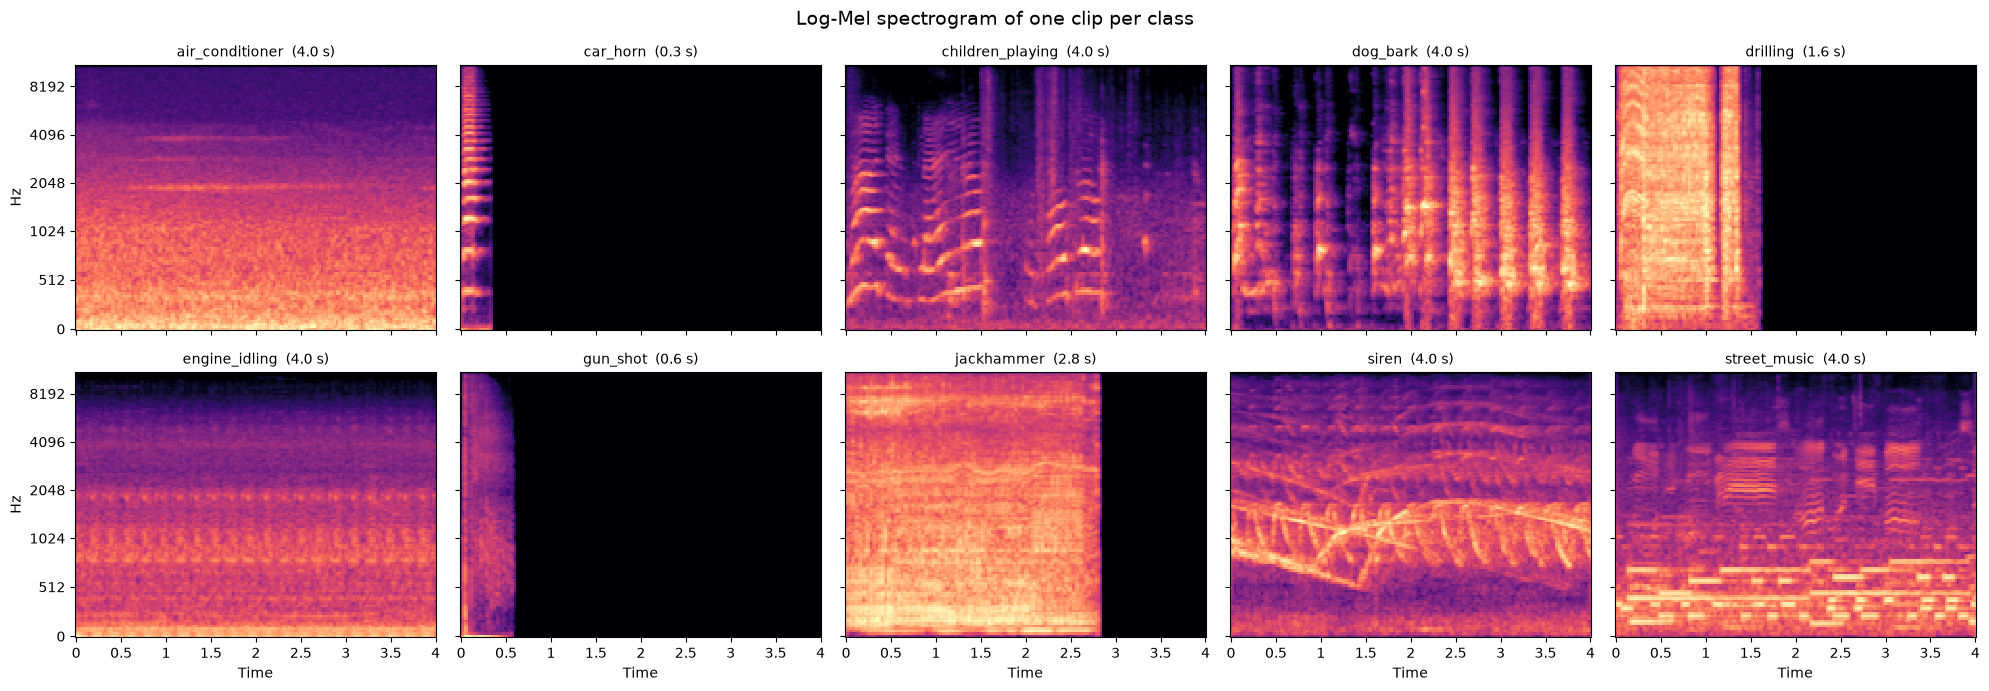

In [3]:
def show(ax, spec, title, y_axis="mel", outer=True):
    librosa.display.specshow(spec, sr=SAMPLE_RATE, hop_length=HOP_LENGTH, x_axis="time", y_axis=y_axis,
                             ax=ax, vmin=0, vmax=1, cmap="magma")
    ax.set_title(title, fontsize=10)
    if outer:
        ax.label_outer()

examples = sa.class_examples(index, per_class=1, seed=1)
fig, axes = plt.subplots(2, 5, figsize=(20, 7), sharex=True, sharey=True)
for ax, (i, row) in zip(axes.flat, examples.iterrows()):
    show(ax, X[i], f"{row['class']}  ({row['end'] - row['start']:.1f} s)")
fig.suptitle("Log-Mel spectrogram of one clip per class", fontsize=14)
fig.tight_layout()
fig.savefig(FIGURES / "logmel_per_class.png", dpi=120)
plt.show()

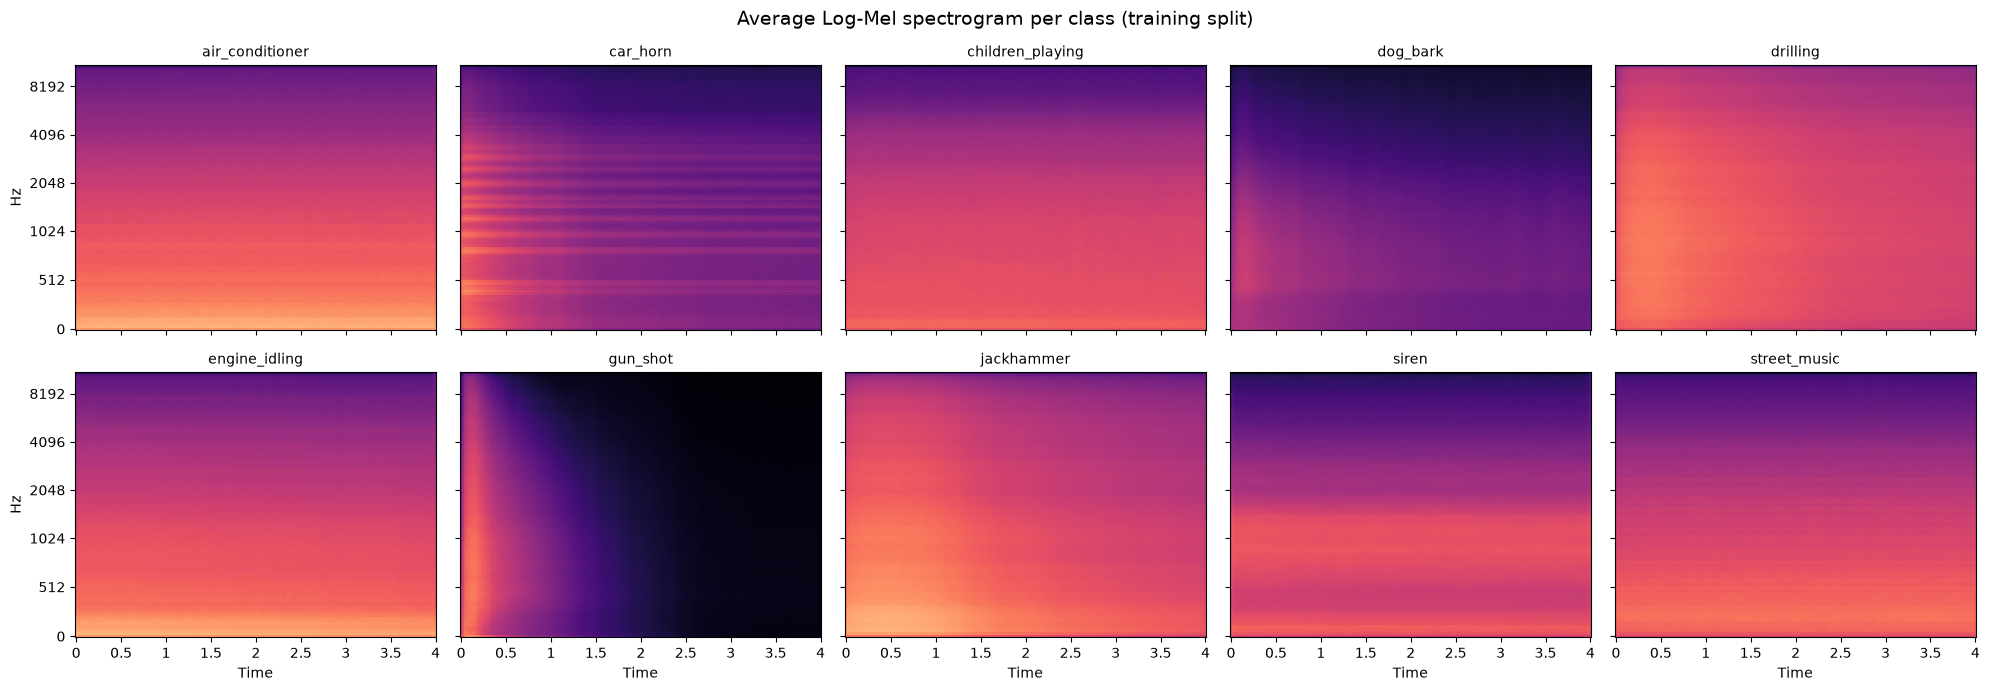

In [4]:
means = sa.class_means(X, index, "train")
fig, axes = plt.subplots(2, 5, figsize=(20, 7), sharex=True, sharey=True)
for ax, c in zip(axes.flat, range(len(CLASS_NAMES))):
    show(ax, means[c], CLASS_NAMES[c])
fig.suptitle("Average Log-Mel spectrogram per class (training split)", fontsize=14)
fig.tight_layout()
fig.savefig(FIGURES / "class_mean_logmel.png", dpi=120)
plt.show()

**Observations.** The class averages separate into three groups. *Short events* concentrate their energy at the start of the clip: gun shots within the first 0.5 s, dog barks fading over the first second; the dark right side is the silence padding of short recordings (96% of gun-shot clips are shorter than 4 s). *Stationary sounds* (air conditioner, engine idling, drilling, children playing, street music) spread their energy evenly over time; air conditioner and engine idling sit mostly below 500 Hz, while drilling and street music are broadband. *Tonal sounds* show horizontal structure: car horns have evenly spaced harmonic stripes, and sirens concentrate in a band around 500–2,000 Hz. The CNN therefore needs both time patterns (onsets, duration) and frequency patterns (harmonics, bands), which is what the 3×3 convolutions over the full 128 × 173 spectrogram can learn. The most informative content lies in the first three seconds, so a 128-frame random crop is a reasonable training augmentation, as long as the crop stays inside the part of short clips that holds sound.

## 3. STFT versus Log-Mel

Both representations come from the same preprocessed clip (22,050 Hz, mono, 4 s, peak-normalized) with the same 2,048-point FFT and 512-sample hop. The STFT keeps all 1,025 linear frequency bins; the Log-Mel spectrogram groups them into 128 mel bands, which are narrow at low frequencies and wide at high frequencies, like human hearing.

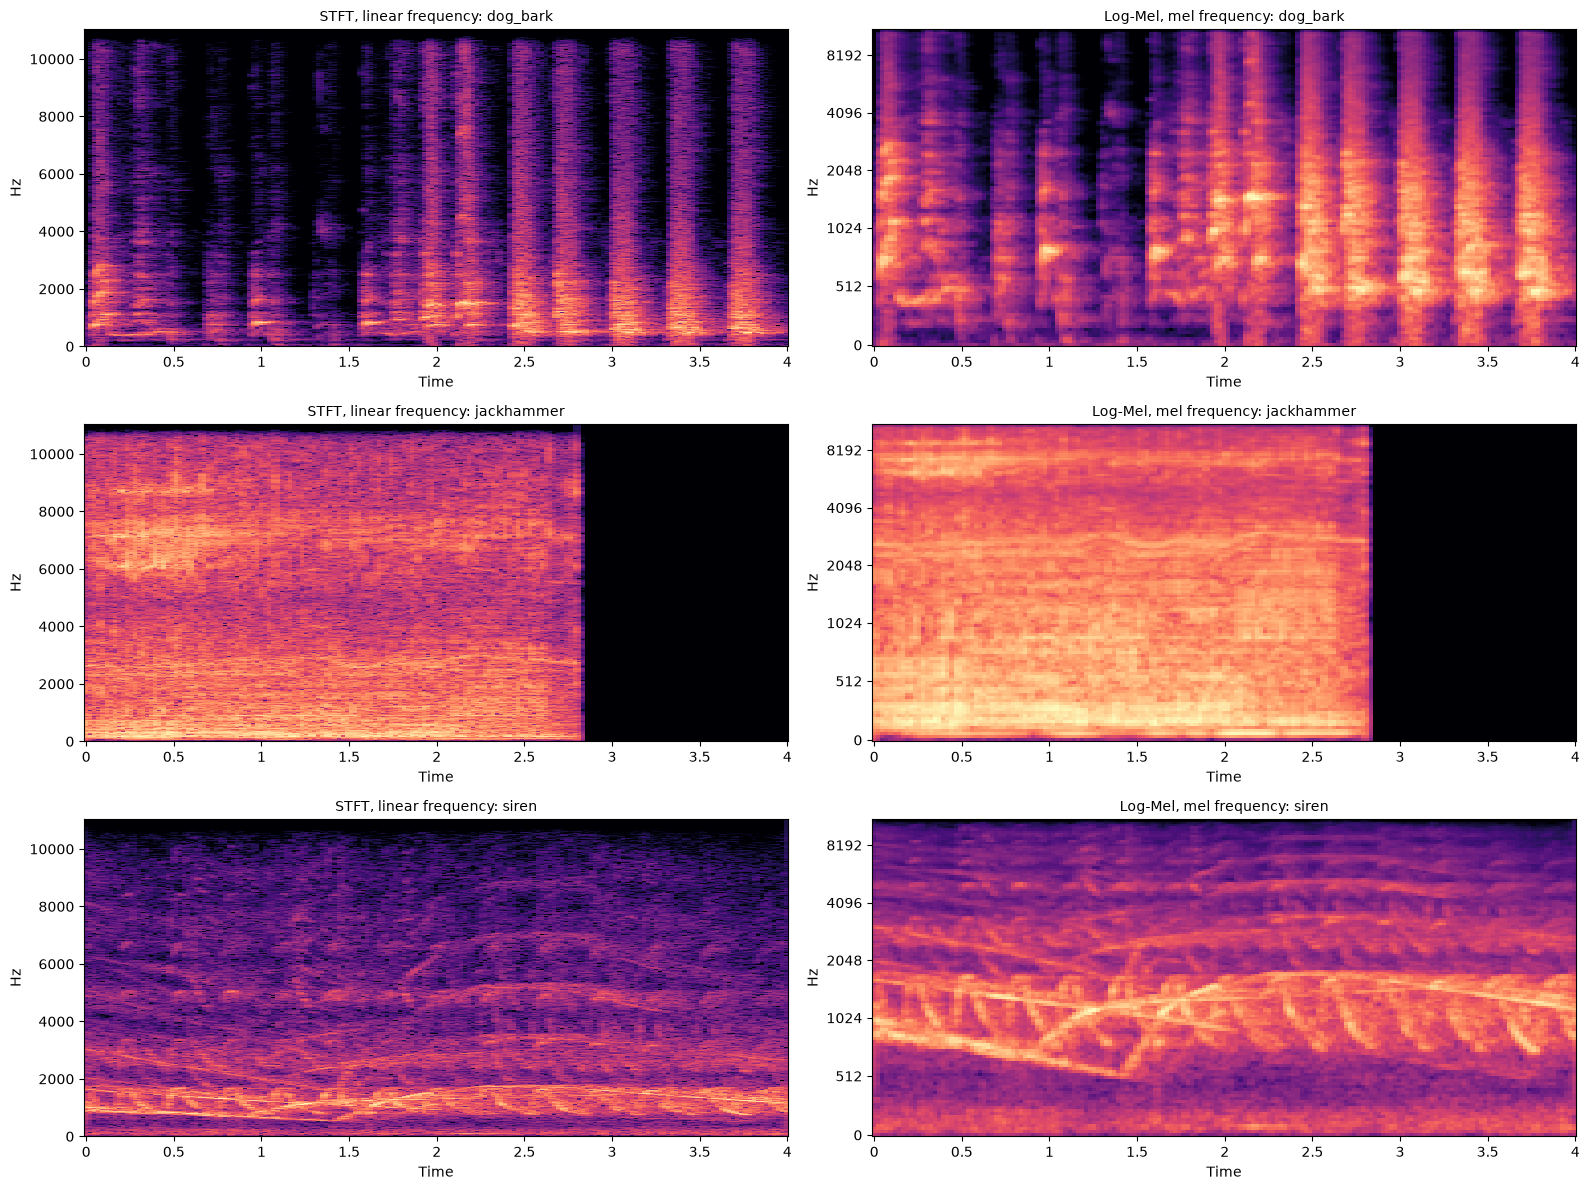

,frequency bins,time frames,frequency axis,values per clip,KB per clip (float32),"GB for 8,732 clips",size vs Log-Mel
representation,,,,,,,
STFT,1025,173,10.8 Hz per bin (linear),177325,692.7,5.77,8.0
Log-Mel,128,173,128 mel bands,22144,86.5,0.72,1.0


In [5]:
root = get_dataset_path()
chosen = examples[examples["class"].isin(["dog_bark", "siren", "jackhammer"])]

fig, axes = plt.subplots(len(chosen), 2, figsize=(16, 4 * len(chosen)))
for (_, row), (ax_stft, ax_mel) in zip(chosen.iterrows(), axes):
    specs = sa.representations(preprocess_audio(str(audio_file(row, root))))
    show(ax_stft, specs["STFT"], f"STFT, linear frequency: {row['class']}", y_axis="linear", outer=False)
    show(ax_mel, specs["Log-Mel"], f"Log-Mel, mel frequency: {row['class']}", outer=False)
fig.tight_layout()
fig.savefig(FIGURES / "stft_vs_logmel.png", dpi=120)
plt.show()

display(sa.representation_table(specs))

### Quantitative comparison

Images alone do not show which representation is easier to classify, so the same simple baseline is trained on both: the mean and standard deviation of every frequency bin over time, standardized, then a logistic regression. It is fitted on a class-balanced sample of the training split and scored on the full validation fold. It is not the CNN; it only checks how much class information each representation carries for the same effort.

Decoding the audio takes a few minutes.

In [6]:
PER_CLASS = 60  # training clips per class; raise it for a more precise comparison
train_rows = sa.sample_rows(index, "train", per_class=PER_CLASS, seed=0)
validation_rows = sa.sample_rows(index, "validation")

train_vectors, y_train = sa.summary_features(train_rows, root, progress=tqdm)
validation_vectors, y_validation = sa.summary_features(validation_rows, root, progress=tqdm)
comparison = sa.compare_representations(train_vectors, y_train, validation_vectors, y_validation)
display(comparison)

stft, mel = comparison.loc["STFT"], comparison.loc["Log-Mel"]
size_ratio = sa.representation_table(specs).loc["STFT", "size vs Log-Mel"]
print(f"Log-Mel: {mel['validation accuracy']:.1%} accuracy, STFT: {stft['validation accuracy']:.1%} "
      f"({(mel['validation accuracy'] - stft['validation accuracy']) * 100:+.1f} points for Log-Mel), "
      f"with {size_ratio:.0f}x fewer values per clip.")

  0%|          | 0/600 [00:00<?, ?it/s]

  0%|          | 0/816 [00:00<?, ?it/s]

,features,validation accuracy,validation macro F1,fit seconds
representation,,,,
STFT,2050,0.458,0.469,1.73
Log-Mel,256,0.457,0.481,0.12


Log-Mel: 45.7% accuracy, STFT: 45.8% (-0.1 points for Log-Mel), with 8x fewer values per clip.


## 4. Input dimensions and structure

* **Frequency axis:** 128 mel bands between 0 and 11,025 Hz (half the sampling rate).
* **Time axis:** 173 frames. With a 512-sample hop at 22,050 Hz one frame is about 23 ms, and 1 + 88,200 / 512 = 173 frames cover the 4 s clip.
* **Values:** decibels relative to each clip's maximum, clipped at -80 dB and scaled to [0, 1]. Zero is silence, including padding.
* **Channels:** one, like a grayscale image. PyTorch expects channels first, so a batch has shape (batch, 1, 128, 173).

Clips shorter than 4 s are padded with silence at the end, so part of their input is empty:

,clips,mean_seconds,share_shorter_than_4s
class,,,
air_conditioner,1000,3.995,0.003
car_horn,429,2.457,0.527
children_playing,1000,3.962,0.024
dog_bark,1000,3.149,0.325
drilling,1000,3.548,0.195
engine_idling,1000,3.936,0.039
gun_shot,374,1.649,0.957
jackhammer,1000,3.611,0.196
siren,929,3.910,0.034


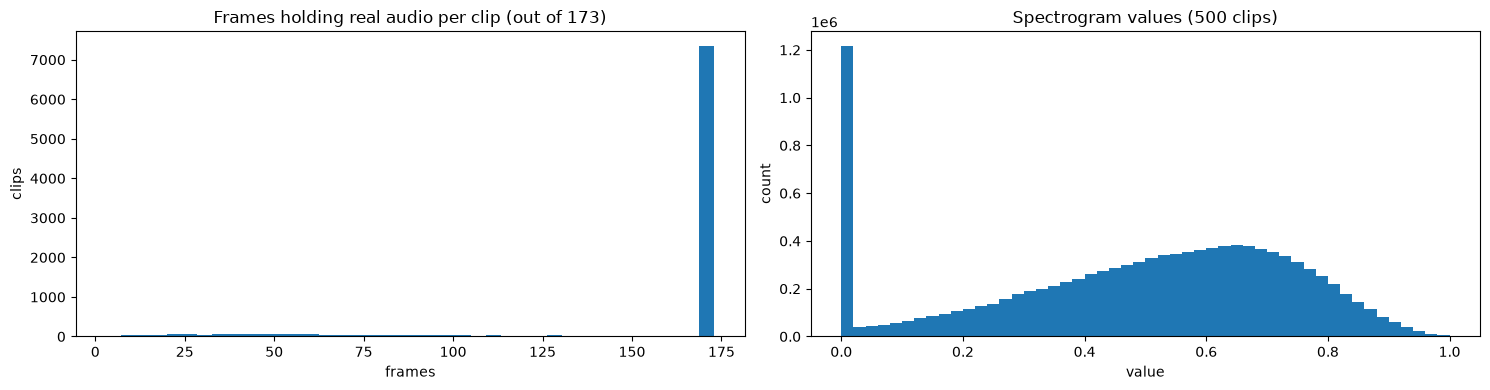

16.0% of clips are shorter than 4 s; padding makes up 9.8% of all frames.


In [7]:
display(sa.duration_table(index))

frames = sa.content_frames(index)
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].hist(frames, bins=40)
axes[0].set(title="Frames holding real audio per clip (out of 173)", xlabel="frames", ylabel="clips")
axes[1].hist(sample.ravel(), bins=50)
axes[1].set(title=f"Spectrogram values ({len(picked)} clips)", xlabel="value", ylabel="count")
fig.tight_layout()
plt.show()

print(f"{(frames < sa.TOTAL_FRAMES).mean():.1%} of clips are shorter than 4 s; "
      f"padding makes up {1 - frames.sum() / (sa.TOTAL_FRAMES * len(frames)):.1%} of all frames.")

## 5. Selected representation: Log-Mel

* **Smaller input:** 22,144 values per clip instead of 177,325 (8 times fewer). That means fewer activations, faster training and less memory for the same CNN.
* **Better use of frequency resolution:** much of the identifying energy of urban sounds lies below a few kHz. The mel scale keeps fine resolution there and merges the high bins, where the STFT spends most of its 1,025 bins.
* **Compact and stable for learning:** the log (decibel) scale compresses the large dynamic range of the recordings, and the mel bands smooth out single-bin noise.
* **Baseline check:** the comparison in section 3 measures how both representations do with the same simple classifier. Log-Mel is kept unless STFT is clearly better there, which would not justify an 8 times larger input on its own.
* Log-Mel spectrograms are also the usual input for CNNs on UrbanSound8K, which makes the results easier to compare with published work.

**Baseline result.** With the same linear classifier, STFT reached 45.8% validation accuracy (macro F1 0.469) and Log-Mel 45.7% (macro F1 0.481). The 0.1-point accuracy gap is far below the sampling error of a 816-clip validation fold (about ±1.7 points), and Log-Mel is slightly better on macro F1, so it is more even across classes. Log-Mel therefore keeps the same class information as the STFT with 8 times fewer values per clip and a 14 times faster fit, which confirms it as the CNN input. Both are far above the 10% chance level; the CNN is expected to improve on this baseline because it also uses the time structure that the mean/std summary discards.

## 6. Final CNN input shape: 1 x 128 x 173

The task suggests 128 x 128 as an example. Two ways would produce it from a 4 s clip, and both cost information:

In [8]:
crop_frames = 128
lost = np.clip(frames - crop_frames, 0, None).sum() / frames.sum()
print(f"Cropping to {crop_frames} frames ({crop_frames * HOP_LENGTH / SAMPLE_RATE:.2f} s) drops {lost:.1%} of all real audio frames.")
print(f"Resizing 173 frames to 128 squeezes time by {173 / 128:.2f}x and changes the duration of every sound event.")

Cropping to 128 frames (2.97 s) drops 24.4% of all real audio frames.
Resizing 173 frames to 128 squeezes time by 1.35x and changes the duration of every sound event.


The CNN therefore takes the full **1 x 128 x 173** spectrogram (channels x mel bands x frames):

* no audio content is dropped and no event is distorted;
* the network ends with global average pooling, so the classifier does not depend on the exact width. A 128 x 128 random crop can still be used later as training augmentation (Member 3) without changing the model;
* the shape matches the cached features, so no resizing step is needed in the DataLoader.

## 7. Check the input shape against the CNN

The architecture is defined in `src/model.py` (Step 2.2). One real batch goes through the untrained network.

In [9]:
from src.datasets import SpectrogramDataset
from src.model import UrbanSoundCNN, model_summary

model = UrbanSoundCNN()
print(model_summary(model))

loader = torch.utils.data.DataLoader(SpectrogramDataset("train"), batch_size=16, shuffle=True)
x, y = next(iter(loader))
with torch.no_grad():
    logits = model.eval()(x)
loss = torch.nn.functional.cross_entropy(logits, y)
print(f"\nBatch {tuple(x.shape)} -> logits {tuple(logits.shape)}")
print(f"Untrained loss {loss.item():.3f} (random guessing over 10 classes gives about ln(10) = 2.303)")

Layer         Type          Output shape                Params
--------------------------------------------------------------
input                       (1, 128, 173)                     
features.0.0  Conv2d        (32, 128, 173)                 288
features.0.1  BatchNorm2d   (32, 128, 173)                  64
features.0.2  ReLU          (32, 128, 173)                   0
features.0.3  Conv2d        (32, 128, 173)               9,216
features.0.4  BatchNorm2d   (32, 128, 173)                  64
features.0.5  ReLU          (32, 128, 173)                   0
features.0.6  MaxPool2d     (32, 64, 86)                     0
features.0.7  Dropout2d     (32, 64, 86)                     0
features.1.0  Conv2d        (64, 64, 86)                18,432
features.1.1  BatchNorm2d   (64, 64, 86)                   128
features.1.2  ReLU          (64, 64, 86)                     0
features.1.3  Conv2d        (64, 64, 86)                36,864
features.1.4  BatchNorm2d   (64, 64, 86)               

## Summary

* Input representation: **Log-Mel spectrogram**, 128 mel bands, 2,048-point FFT, 512-sample hop, decibels scaled to [0, 1].
* Input shape: **(1, 128, 173)** per clip, **(batch, 1, 128, 173)** per batch.
* Splits: folds 1 to 8 for training, fold 9 for validation, fold 10 for testing, as provided by `src.datasets.make_dataloaders`.
* The figures `logmel_per_class.png`, `class_mean_logmel.png` and `stft_vs_logmel.png` are saved in `figures/` for the report.